# Sleep Staging with HMMs: Exploratory Data Analysis (NBK 2)

This notebook explores the features and expert labels built in NBK 1 before any model is trained. It looks at how common each stage is, which features separate the stages, whether the features are close to Gaussian within a stage, how the experts' stages follow each other, and how N3 and REM change over the night. Each of these relates to a part of the HMM: the class balance behind our metrics, the Gaussian emissions, and the transition matrix.

---

### Import statements

In [21]:
import os
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
import helpers

---

### Loading the processed data

We load the features and the stage counts, and check that both come from the same run of NBK 1: every recording should have the same number of epochs in both files. Sequences are unbroken runs of epochs, so a new one starts at each recording and after each gap.

In [22]:
features = helpers.load_features()
counts = pd.read_csv(os.path.join(helpers.PROC, "stage_counts.csv"))
ALL = helpers.FEATURE_SETS["EEG+EOG"]

after = counts[counts["when"] == "after"].set_index("recording")[helpers.STAGES].sum(axis=1)
assert (features.groupby("recording").size() == after).all()

lengths = helpers.sequence_lengths(features)
hours = (features.groupby("recording")["epoch"].agg(lambda e: e.max() - e.min() + 1)
         * helpers.EPOCH_SEC / 3600)
print(f"{len(features):,} epochs, {features['recording'].nunique()} recordings, "
      f"{features['subject'].nunique()} subjects, {len(lengths)} sequences")
print(f"Recording length after trimming: median {hours.median():.1f} h, "
      f"range {hours.min():.1f} to {hours.max():.1f} h")
features.head()

170,252 epochs, 153 recordings, 78 subjects, 293 sequences
Recording length after trimming: median 8.9 h, range 5.6 to 19.3 h


,recording,subject,night,epoch,stage,delta,theta,alpha,sigma,beta,eog_slow,eog_fast
0,SC4001,00,1,961,W,0.387373,0.526692,-0.701014,0.500110,1.876909,1.100830,1.282945
1,SC4001,00,1,962,W,0.727017,1.078730,-0.741029,-0.375787,1.962123,1.619028,1.865848
2,SC4001,00,1,963,W,1.062475,1.780850,-0.515158,-0.285826,1.647870,1.968462,2.429079
3,SC4001,00,1,964,W,0.789377,1.277112,-0.213716,0.628644,2.548154,2.201217,2.122541
4,SC4001,00,1,965,W,0.691628,0.930214,-0.609981,0.076634,1.899210,1.999572,1.984470


There are 170,252 epochs from 153 recordings and 78 subjects, in 293 sequences. After trimming, a recording has a median length of 8.9 hours, but the range is wide (5.6 to 19.3 hours). Most of the longest windows contain long stretches awake.

---

### Stage distribution before and after trimming

The HMM learns from how often each stage occurs, and our metrics depend on it too. We compare the share of each stage before and after trimming.

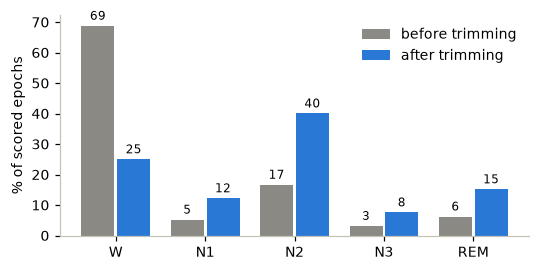

when,before (n),after (n),before (%),after (%)
W,285433,42563,68.8,25.0
N1,21522,20808,5.2,12.2
N2,69132,68156,16.7,40.0
N3,13039,12923,3.1,7.6
REM,25835,25802,6.2,15.2


In [23]:
totals = counts.groupby("when")[helpers.STAGES].sum().loc[["before", "after"]]
shares = totals.div(totals.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(5.5, 2.6))
x = np.arange(len(helpers.STAGES))
for shift, when, color in [(-0.2, "before", helpers.GRAY), (0.2, "after", helpers.BLUE)]:
    bars = ax.bar(x + shift, shares.loc[when], width=0.37, color=color, label=f"{when} trimming")
    ax.bar_label(bars, fmt="%.0f", fontsize=8, padding=2)
ax.set_xticks(x, helpers.STAGES)
ax.set_ylabel("% of scored epochs")
ax.legend()
helpers.save_figure(fig, "stage_distribution.png")
plt.show()

pd.concat([totals.T.add_suffix(" (n)"), shares.T.round(1).add_suffix(" (%)")], axis=1)

Before trimming, 68.8% of scored epochs are wake. After trimming, wake is 25.0% and N2 is the largest class at 40.0%, while N1 (12.2%) and N3 (7.6%) are rare. This is important to note because a model that always guesses N2 would be right 40% of the time, so accuracy alone can look good even if the rare stages are missed. This is why we also report Cohen's kappa, macro-F1, and per-stage results.

---

### Features by sleep stage

For the HMM to tell stages apart, the features must differ between them. We show the mean of each z-scored feature by stage, the share of each feature's variance that stage explains, and how far apart every pair of stages is on each feature, in pooled standard deviations (the sign shows which stage is higher). The heatmap shows the stage averages, and the second table also accounts for the spread within each stage.

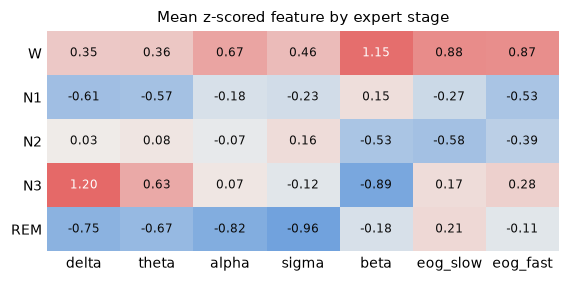

,delta,theta,alpha,sigma,beta,eog_slow,eog_fast
variance explained,0.27,0.17,0.22,0.21,0.51,0.35,0.29


,delta,theta,alpha,sigma,beta,eog_slow,eog_fast,best,best feature
N1 vs REM,0.19,0.12,0.75,0.93,0.50,-0.53,-0.56,0.93,sigma
N1 vs N2,-0.88,-0.89,-0.13,-0.48,1.02,0.45,-0.28,1.02,beta
W vs N1,0.90,0.83,0.85,0.70,1.20,1.26,1.37,1.37,eog_fast
N2 vs REM,1.17,1.08,0.95,1.45,-0.62,-0.95,-0.40,1.45,sigma
W vs REM,1.07,0.94,1.54,1.49,1.74,0.65,0.85,1.74,beta
W vs N2,0.32,0.26,0.79,0.31,2.16,1.73,1.27,2.16,beta
N2 vs N3,-2.25,-0.92,-0.18,0.36,0.62,-1.44,-1.57,2.25,delta
W vs N3,-0.90,-0.26,0.62,0.60,2.60,0.88,0.60,2.60,beta
N1 vs N3,-2.84,-1.74,-0.29,-0.14,1.55,-0.70,-1.66,2.84,delta
N3 vs REM,3.43,2.02,1.09,1.12,-1.24,-0.05,0.54,3.43,delta


In [24]:
means = features.groupby("stage")[ALL].mean().loc[helpers.STAGES]

fig, ax = plt.subplots(figsize=(6, 2.6))
helpers.heatmap(ax, means, helpers.STAGES, ALL, cmap=helpers.DIVERGING, vmin=-1.5, vmax=1.5)
ax.set_title("Mean z-scored feature by expert stage")
helpers.save_figure(fig, "features_by_stage.png")
plt.show()

between = sum(len(g) * (g[ALL].mean() - features[ALL].mean()) ** 2
              for _, g in features.groupby("stage"))
eta = between / ((features[ALL] - features[ALL].mean()) ** 2).sum()

def separation(a, b):
    A, B = features.loc[features["stage"] == a, ALL], features.loc[features["stage"] == b, ALL]
    return (A.mean() - B.mean()) / np.sqrt((A.var() + B.var()) / 2)

pairs = pd.DataFrame({f"{a} vs {b}": separation(a, b)
                      for a, b in combinations(helpers.STAGES, 2)}).T
largest = pairs.abs()
pairs["best"] = largest.max(axis=1)
pairs["best feature"] = largest.idxmax(axis=1)

display(eta.rename("variance explained").to_frame().T.round(2))
pairs.sort_values("best").round(2)

Wake has the highest beta (1.15) and EOG power, N3 has the highest delta (1.20) and the lowest beta, and REM is below average in every EEG band, most of all in sigma. Beta is the most informative single feature, with stage explaining 51% of its variance.

The pairs are sorted from hardest to easiest by their best single feature. **N1 and REM are the hardest pair** (0.93, from sigma), and **the three hardest pairs all involve N1**: N1 vs REM, N1 vs N2 (1.02), and W vs N1 (1.37). N1 and REM barely differ in delta (0.19) and theta (0.12). The EOG features separate them by about 0.5, with more EOG power in REM, consistent with more eye movement. That is less than sigma and alpha do on their own, but it comes from a different signal. N1 also sits between wake and REM on every EEG feature, so we expect it to be confused with both.

N2 and N3 are well separated in delta (2.25). These numbers look at one feature at a time, while the HMM uses all of them together, so stages can be easier to tell apart than the table suggests.

---

### Checking the Gaussian assumption

Our HMM assumes that the features of each stage follow one multivariate Gaussian. We compare the histogram of every feature in every stage with a fitted Gaussian. We then look at the correlations between the EEG features within each stage, and measure skewness and excess kurtosis (both are 0 for a Gaussian) for all seven features.

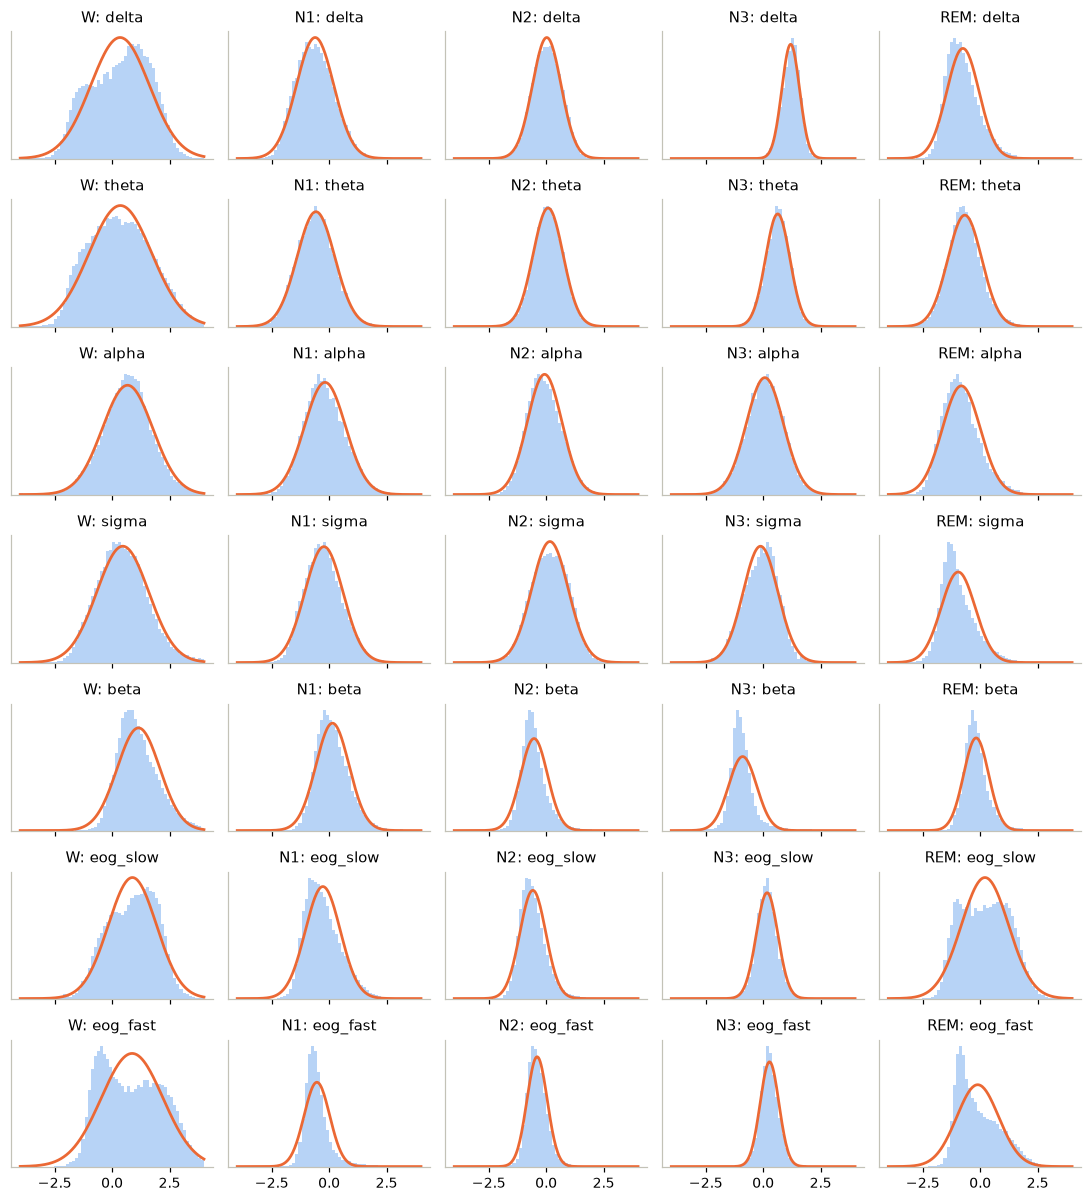

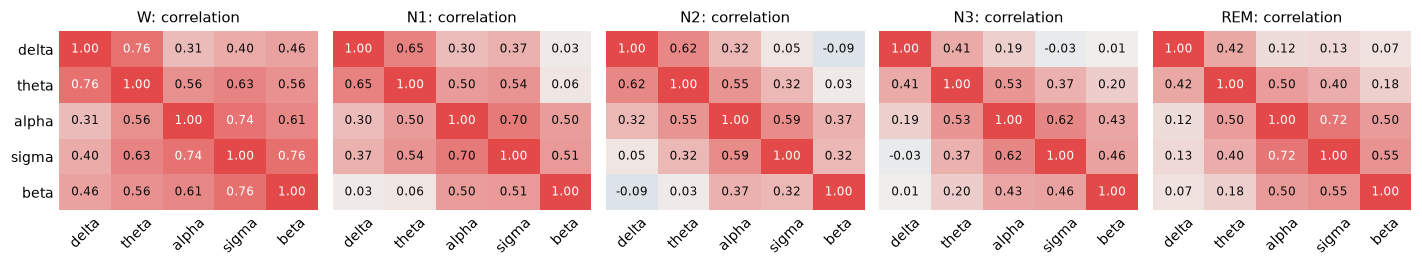

delta                 theta                 alpha                 sigma  \
       skew excess kurtosis  skew excess kurtosis  skew excess kurtosis  skew   
stage                                                                           
W     -0.20           -0.71  0.17           -0.43  0.11            1.05  0.44   
N1     0.27           -0.16  0.13            0.20  0.34            0.40  0.44   
N2    -0.06           -0.18  0.00            0.38  0.35            0.21  0.03   
N3    -0.44            1.11 -0.17            0.26 -0.02            0.25 -0.16   
REM    0.76            0.71  0.32            0.67  0.65            0.79  0.97   

                       beta                 eog_slow                 eog_fast  \
      excess kurtosis  skew excess kurtosis     skew excess kurtosis     skew   
stage                                                                           
W                0.94  0.76            1.40    -0.16           -0.59     0.26   
N1               0.73  0.83            1.71     0.66            0.29     1.81   
N2              -0.23  1.39            4.73     0.93            1.83     1.05   
N3               0.33  2.30           10.19     0.32            1.62     0.55   
REM              1.68  1.34            4.54     0.10           -0.93     0.73   

                       
      excess kurtosis  
stage                  
W               -0.86  
N1               5.88  
N2               3.73  
N3               2.70  
REM             -0.24

In [25]:
fig, axes = plt.subplots(len(ALL), 5, figsize=(10, 11), sharex=True)
grid = np.linspace(-4, 4, 200)
for row, feature in enumerate(ALL):
    for ax, stage in zip(axes[row], helpers.STAGES):
        x = features.loc[features["stage"] == stage, feature]
        ax.hist(x, bins=60, range=(-4, 4), density=True, color="#b7d3f6")
        ax.plot(grid, norm.pdf(grid, x.mean(), x.std()), color=helpers.ORANGE)
        ax.set_yticks([])
        ax.set_title(f"{stage}: {feature}")
fig.tight_layout()
helpers.save_figure(fig, "gaussian_check.png")
plt.show()

fig, axes = plt.subplots(1, 5, figsize=(13, 2.5), sharey=True)
for ax, stage in zip(axes, helpers.STAGES):
    corr = features.loc[features["stage"] == stage, helpers.EEG_FEATURES].corr()
    helpers.heatmap(ax, corr, helpers.EEG_FEATURES, helpers.EEG_FEATURES,
                    cmap=helpers.DIVERGING, vmin=-1, vmax=1)
    ax.set_title(f"{stage}: correlation")
    ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()

shape = features.groupby("stage")[ALL].agg(["skew", pd.Series.kurt])
shape.loc[helpers.STAGES].rename(columns={"kurt": "excess kurtosis"}).round(2)

The assumption holds well for some features and poorly for others. **Theta, alpha, and sigma are close to Gaussian in almost every stage**, and so is delta outside wake. Where the fit fails, it fails in one of three ways:

- **Too peaked, with a long right tail:** Beta looks like this in every stage, worst in N3 (excess kurtosis 10.19), even after the log. Sigma in REM and fast EOG in N1 look similar, and fast EOG in REM is lopsided. In N1, fast EOG has an excess kurtosis of 5.88, so the Gaussian assumption is weakest for the EOG in the stage it was meant to help with.
- **Two groups instead of one:** Delta and fast EOG in wake both have two humps, which a single Gaussian cannot represent.
- **Too flat:** Slow EOG in REM is broad and flat-topped (excess kurtosis −0.93).

The histograms and the table do not always agree. Wake has the smallest skewness and kurtosis overall, yet two of its features have two humps, which those two numbers do not detect. A mixture of Gaussians per stage could capture these shapes.

The features are also correlated within a stage, most strongly in wake. This is why we use full covariances, as a diagonal covariance would assume that the features are independent given the stage.

---

### Expert stage transitions

The transition matrix is the part of the HMM that models the order of sleep. Before learning one, we look at the experts' own transitions, counted within sequences only. A typical cycle runs N1, N2, N3, back to N2, and then REM.

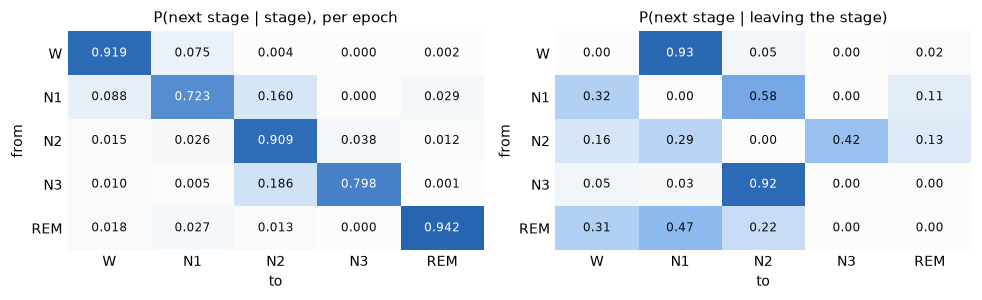

Leaving N3: 92% go to N2 and 0.5% go to REM
REM is entered from: {'W': '5%', 'N1': '40%', 'N2': '54%', 'N3': '1%', 'REM': '0%'}
Mean stage duration in minutes: {'W': 6.2, 'N1': 1.8, 'N2': 5.5, 'N3': 2.5, 'REM': 8.6}


In [26]:
codes = helpers.collapse(features["stage"], 5)
trans = helpers.transition_counts(codes, lengths, 5)
P = trans / trans.sum(axis=1, keepdims=True)

leave = trans * (1 - np.eye(5))
leave = leave / leave.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
helpers.heatmap(axes[0], P, helpers.STAGES, helpers.STAGES, fmt="{:.3f}")
axes[0].set_title("P(next stage | stage), per epoch")
helpers.heatmap(axes[1], leave, helpers.STAGES, helpers.STAGES)
axes[1].set_title("P(next stage | leaving the stage)")
for ax in axes:
    ax.set_ylabel("from")
    ax.set_xlabel("to")
fig.tight_layout()
helpers.save_figure(fig, "expert_transitions.png")
plt.show()

W, N1, N2, N3, REM = range(5)
print(f"Leaving N3: {leave[N3, N2]:.0%} go to N2 and {leave[N3, REM]:.1%} go to REM")
entries = trans[:, REM].copy()
entries[REM] = 0
print("REM is entered from:", {s: f"{v:.0%}" for s, v in zip(helpers.STAGES, entries / entries.sum())})
print("Mean stage duration in minutes:",
      {s: round(float(0.5 / (1 - P[i, i])), 1) for i, s in enumerate(helpers.STAGES)})

Stages are persistent: the chance of staying in the same stage in the next epoch is 0.91 to 0.94 for wake, N2, and REM, and lower for N3 (0.80) and N1 (0.72). When the sleeper leaves N3, **92% of the time they go to N2 and only 0.5% to REM**. REM is mostly entered from N2 (54%) and N1 (40%), and wake leads almost only to N1. This matches the expected cycle, so a good transition matrix should show the same pattern.

The mean stage durations range from 1.8 minutes for N1 to 8.6 minutes for REM. An HMM assumes that durations follow a geometric distribution, which makes very short bouts the most likely, so it may not fit long REM periods well.

---

### N3 and REM across the night

N3 is expected to be more common early in the night and REM later. We compute the share of N3 and REM among sleep epochs by how much of the sleep period has passed, from the first sleep epoch to the last.

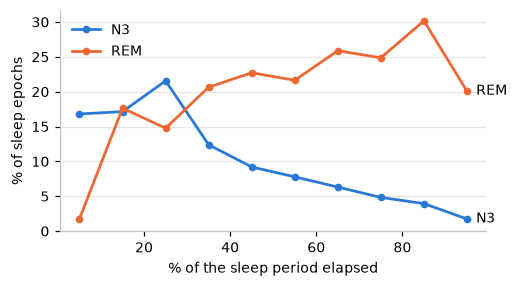

stage,N1,N2,N3,REM
third,,,,
early,16.7,53.2,18.2,12.0
middle,12.5,55.6,8.6,23.2
late,20.0,51.1,3.8,25.1


In [27]:
position = helpers.night_position(features)
asleep = features[(features["stage"] != "W") & position.notna()]
tenth = np.minimum((position[asleep.index] * 10).astype(int), 9)
by_tenth = pd.crosstab(tenth, asleep["stage"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(5, 2.6))
for stage, color in [("N3", helpers.BLUE), ("REM", helpers.ORANGE)]:
    ax.plot(by_tenth.index * 10 + 5, by_tenth[stage], color=color, marker="o", ms=4, label=stage)
    ax.annotate(stage, (95, by_tenth[stage].iloc[-1]), xytext=(6, 0),
                textcoords="offset points", va="center")
ax.set_xlabel("% of the sleep period elapsed")
ax.set_ylabel("% of sleep epochs")
ax.set_ylim(0)
ax.grid(axis="y")
ax.legend()
helpers.save_figure(fig, "overnight_expert.png")
plt.show()

third = pd.cut(position[asleep.index], [0, 1/3, 2/3, 1], include_lowest=True,
               labels=["early", "middle", "late"])
(pd.crosstab(third, asleep["stage"], normalize="index") * 100).rename_axis("third").round(1)[helpers.STAGES[1:]]

The overall pattern matches what we expected. N3 falls from 18.2% of sleep in the first third of the sleep period to 8.6% and then 3.8%, while REM rises from 12.0% to 23.2% and then 25.1%. The figure shows more detail: REM is almost absent at the very start, N3 peaks about a quarter of the way through, and REM dips again at the end. A standard HMM has one fixed transition matrix for the whole night, so it cannot represent this change directly. Any overnight trend in its predictions has to come from the features.

---

### Example hypnogram

We plot one night to see what the data looks like. To avoid picking a night by eye, we choose by a rule: the recording whose stage mix in each third of the sleep period is closest to the average one (the sum of squared differences in stage shares). This matches the timing of the stages as well as their amounts. We show its expert hypnogram with two features, delta and beta (smoothed over five epochs). The links open the first N3 and REM epochs in [LightWAVE](https://www.physionet.org/lightwave/?db=sleep-edfx/1.0.0), which shows the signals but not the stages.

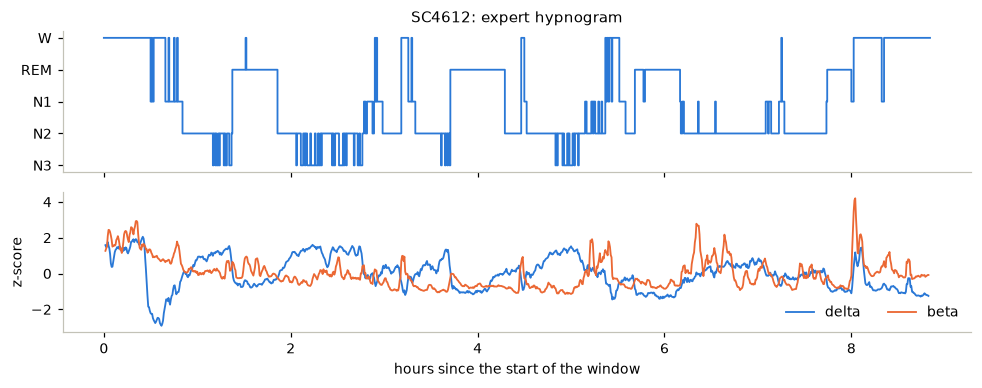

First N3: https://www.physionet.org/lightwave/?db=sleep-edfx/1.0.0&record=sleep-cassette/SC4612E0-PSG.edf&t0=09:44:00
First REM: https://www.physionet.org/lightwave/?db=sleep-edfx/1.0.0&record=sleep-cassette/SC4612E0-PSG.edf&t0=09:56:30


In [28]:
position = helpers.night_position(features)
third = pd.cut(position, [0, 1/3, 2/3, 1], include_lowest=True, labels=["early", "middle", "late"])
asleep = features[(features["stage"] != "W") & third.notna()].assign(third=third)
profile = pd.crosstab([asleep["recording"], asleep["third"]], asleep["stage"], normalize="index").unstack("third")
average = pd.crosstab(asleep["third"], asleep["stage"], normalize="index").unstack()
recording = ((profile - average[profile.columns]) ** 2).sum(axis=1).idxmin()
g = features[features["recording"] == recording]

ORDER = {"W": 4, "REM": 3, "N1": 2, "N2": 1, "N3": 0}
fig, axes = plt.subplots(2, 1, figsize=(9, 3.6), sharex=True)
t = (g["epoch"] - g["epoch"].min()) * helpers.EPOCH_SEC / 3600
axes[0].step(t, g["stage"].map(ORDER), where="post", color=helpers.BLUE, lw=1.2)
axes[0].set_yticks(list(ORDER.values()), list(ORDER))
axes[0].set_title(f"{recording}: expert hypnogram")
axes[1].plot(t, g["delta"].rolling(5, center=True).mean(), color=helpers.BLUE, lw=1.2, label="delta")
axes[1].plot(t, g["beta"].rolling(5, center=True).mean(), color=helpers.ORANGE, lw=1.2, label="beta")
axes[1].set_ylabel("z-score")
axes[1].set_xlabel("hours since the start of the window")
axes[1].legend(ncol=2)
fig.tight_layout()
helpers.save_figure(fig, "example_hypnogram.png")
plt.show()

for stage in ["N3", "REM"]:
    first = g.loc[g["stage"] == stage, "epoch"].iloc[0]
    print(f"First {stage}:", helpers.lightwave_url(helpers.psg_path(recording), first))

SC4612 shows about four sleep cycles, each ending in REM, starting around 1.4, 3.7, 5.7, and 7.7 hours into the window. N3 appears only in the first 5.1 hours and is always entered from N2, which matches the expected N2 to N3 to N2 to REM order. Delta rises during the N3 periods, and beta is highest when the subject is awake, especially at the start of the window.

The cycles here are about two hours long, longer than the textbook 90 minutes, so **individual nights still differ from the average** even when their timing is typical.

---

### Saving figures

Each figure is saved to `figures/` when its cell runs. We list the saved files here. The most useful ones for the report are `features_by_stage.png`, which shows why N1 and REM are hard, and `overnight_expert.png`, which shows the trend that the model cannot represent directly. The others can go in the appendix.

In [29]:
saved = sorted(f for f in os.listdir(helpers.FIG) if f.endswith(".png"))
print(f"{len(saved)} figures in {os.path.basename(helpers.FIG)}/")
for name in saved:
    print(" ", name)

6 figures in figures/
  example_hypnogram.png
  expert_transitions.png
  features_by_stage.png
  gaussian_check.png
  overnight_expert.png
  stage_distribution.png


This notebook saves six figures: `stage_distribution.png`, `features_by_stage.png`, `gaussian_check.png`, `expert_transitions.png`, `overnight_expert.png`, and `example_hypnogram.png`.

---